## EDA

In [38]:
#Charger le dataset de radiographies thoraciques fourni pour le projet.

import kagglehub

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)


Path to dataset files: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia


In [39]:
# Explorer la structure des dossiers et identifier les classes présentes.
from pathlib import Path

data_dir = Path(path) / "chest_xray"

train_dir = data_dir / "train"
test_dir = data_dir / "test"
val_dir = data_dir / "val"

print("Train :", train_dir)
print("Test :", test_dir)
print("Validation :", val_dir)

Train : /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/train
Test : /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/test
Validation : /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/val


In [40]:
# Vérifier le nombre d'images disponibles dans chaque classe.
# Vérifier la répartition des images entre les classes NORMAL et PNEUMONIA.
for nom, dossier in [
    ("Train", train_dir),
    ("Validation", val_dir),
    ("Test", test_dir)
]:
    print(f"\n{nom} :")

    for classe in ["NORMAL", "PNEUMONIA"]:
        classe_dir = dossier / classe

        images = [
            f for f in classe_dir.iterdir()
            if f.is_file()
        ]

        print(f"{classe} : {len(images)} images")



Train :
NORMAL : 1341 images
PNEUMONIA : 3875 images

Validation :
NORMAL : 8 images
PNEUMONIA : 8 images

Test :
NORMAL : 234 images
PNEUMONIA : 390 images


In [41]:
from PIL import Image

for nom, dossier in [
    ("Train", train_dir),
    ("Validation", val_dir),
    ("Test", test_dir)
]:
    erreurs = []

    for classe in ["NORMAL", "PNEUMONIA"]:
        classe_dir = dossier / classe

        for fichier in classe_dir.iterdir():
            if not fichier.is_file():
                continue

            try:
                with Image.open(fichier) as img:
                    img.verify()
            except Exception:
                erreurs.append(fichier)

    print(f"{nom} : {len(erreurs)} images problématiques")

    if erreurs:
        print("Exemples :", erreurs[:5])

Train : 0 images problématiques
Validation : 0 images problématiques
Test : 0 images problématiques


In [42]:
for nom, dossier in [
    ("Train", train_dir),
    ("Test", test_dir),
    ("Validation", val_dir)
]:
    for fichier in dossier.iterdir():
        if fichier.is_dir():
            for image in list(fichier.iterdir())[:1]:
                with Image.open(image) as img:
                    print(
                        f"Ensemble : {nom} | "
                        f"Classe : {fichier.name} | "
                        f"Image : {image.name} | "
                        f"Taille : {img.size} | "
                        f"Mode : {img.mode} | "
                        f"Format : {img.format}"
                    )

Ensemble : Train | Classe : PNEUMONIA | Image : person1180_virus_2010.jpeg | Taille : (1024, 712) | Mode : L | Format : JPEG
Ensemble : Train | Classe : NORMAL | Image : NORMAL2-IM-0771-0001.jpeg | Taille : (1336, 1128) | Mode : L | Format : JPEG
Ensemble : Test | Classe : PNEUMONIA | Image : person1676_virus_2892.jpeg | Taille : (1624, 1104) | Mode : L | Format : JPEG
Ensemble : Test | Classe : NORMAL | Image : NORMAL2-IM-0336-0001.jpeg | Taille : (1612, 941) | Mode : L | Format : JPEG
Ensemble : Validation | Classe : PNEUMONIA | Image : person1947_bacteria_4876.jpeg | Taille : (1152, 664) | Mode : L | Format : JPEG
Ensemble : Validation | Classe : NORMAL | Image : NORMAL2-IM-1431-0001.jpeg | Taille : (1736, 1416) | Mode : L | Format : JPEG


In [43]:
# Charger les images : créer une vraie validation à partir du dossier train.
# Le dossier val original du dataset contient seulement 16 images : il est trop petit.
import tensorflow as tf

IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=False
)

# Garder le dossier test complètement séparé pour l'évaluation finale.
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=False
)

# Précharger les lots suivants sans charger tout le dataset en mémoire.
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Classes :", train_ds.class_names)


Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.


AttributeError: '_PrefetchDataset' object has no attribute 'class_names'

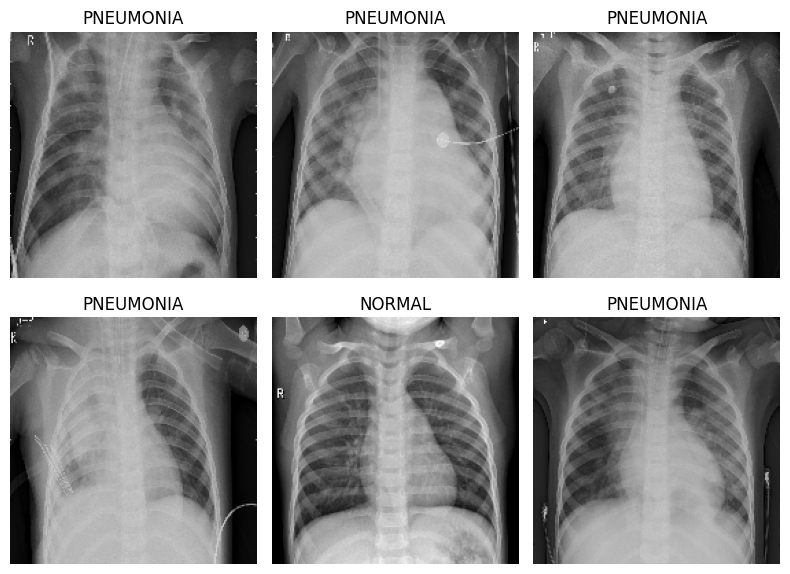

In [ ]:
#Visualisation des radiographies.
import matplotlib.pyplot as plt

class_names = train_ds.class_names

for images, labels in train_ds.take(1):
    plt.figure(figsize=(8, 6))

    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy().squeeze())])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

y_train = np.concatenate([
    labels.numpy().ravel()
    for images, labels in train_ds
]).astype(int)

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Poids des classes :", class_weights)

Poids des classes : {0: 1.9448173005219984, 1: 0.6730322580645162}


In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

model = Sequential([
    # Entrée : images 180 × 180 avec 3 canaux
    Input(shape=(180, 180, 3)),

    # Normalisation : valeurs de 0-255 vers 0-1
    Rescaling(1./255),

    # Bloc convolutionnel 1
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Bloc convolutionnel 2
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Bloc convolutionnel 3
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # GlobalAveragePooling2D remplace Flatten pour réduire le nombre de paramètres
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.metrics import BinaryAccuracy ,Precision,Recall,AUC
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            BinaryAccuracy(name="accuracy"),
            Precision(name="precision"),
            Recall(name="recall"),
            AUC(name="auc"),
        ]
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Arrêter si la validation ne s'améliore plus et restaurer les meilleurs poids.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

# Réduire le taux d'apprentissage si val_loss stagne.
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)


In [ ]:
import time

start = time.time()

history = model.fit(
    train_ds,
    epochs=10
    class_weight=class_weights,
    validation_data=val_ds,
    callbacks=[early_stopping, reduce_lr]
)

end = time.time()
training_duration = end - start

print(f"Durée d'entraînement : {training_duration:.2f} secondes")
print(f"Durée en minutes : {training_duration / 60:.2f} minutes")


Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 198s 1s/step - accuracy: 0.8242 - auc: 0.9188 - loss: 0.3741 - precision: 0.9389 - recall: 0.8165 - val_accuracy: 0.8750 - val_auc: 0.9531 - val_loss: 0.2600 - val_precision: 0.8750 - val_recall: 0.8750
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 197s 1s/step - accuracy: 0.9448 - auc: 0.9834 - loss: 0.1591 - precision: 0.9807 - recall: 0.9443 - val_accuracy: 0.8750 - val_auc: 0.9688 - val_loss: 0.2773 - val_precision: 1.0000 - val_recall: 0.7500
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 197s 1s/step - accuracy: 0.9528 - auc: 0.9901 - loss: 0.1240 - precision: 0.9840 - recall: 0.9520 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.1928 - val_precision: 1.0000 - val_recall: 0.7500
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 201s 1s/step - accuracy: 0.9645 - auc: 0.9939 - loss: 0.0916 - precision: 0.9884 - recall: 0.9636 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.1381 - val_precision: 1.0000 - val_recall: 0.7500
Epoch 5/5
163/163 ━━━━━━━━━━━━━━

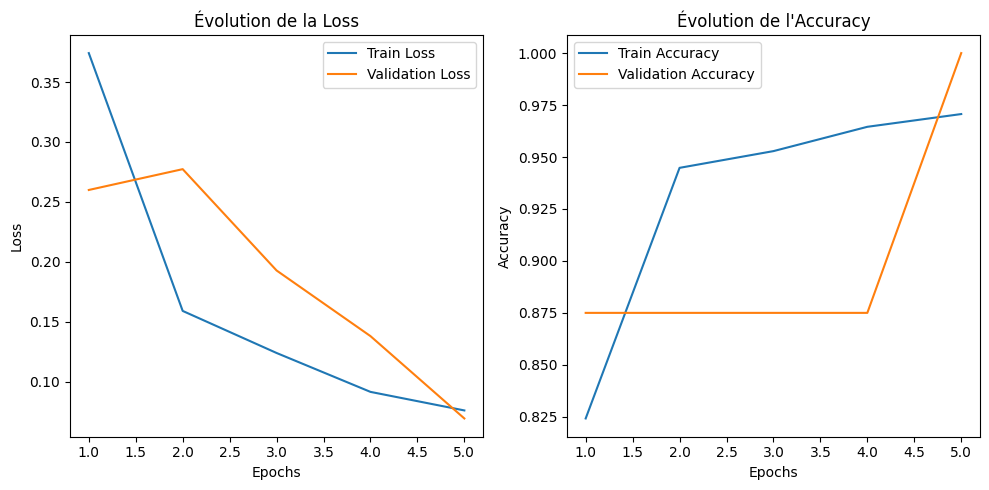

In [ ]:
#visualiser les courbes d'apprentissage
train_loss =history.history["loss"]
val_loss =history.history["val_loss"]

train_accuracy =history.history["accuracy"]
val_accuracy =history.history["val_accuracy"]

epochs =range(1,len(train_loss) + 1)

plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.title("Évolution de la Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracy, label="Train Accuracy")
plt.plot(epochs, val_accuracy, label="Validation Accuracy")
plt.title("Évolution de l'Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
results = model.evaluate(test_ds, return_dict=True)

for metric, value in results.items():
    print(f"{metric} : {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 375ms/step - accuracy: 0.7965 - auc: 0.8982 - loss: 0.8455 - precision: 0.7594 - recall: 0.9872
accuracy : 0.7965
auc : 0.8982
loss : 0.8455
precision : 0.7594
recall : 0.9872


In [ ]:
import numpy as np

# y_true et y_prob doivent provenir du même test_ds, dans le même ordre.
y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

y_prob = model.predict(test_ds, verbose=1).ravel()

# Seuil standard ; ne le régler qu'avec les données de validation, pas le test.
THRESHOLD = 0.5
y_pred = (y_prob >= THRESHOLD).astype(int)


20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 374ms/step


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

              precision    recall  f1-score   support

      NORMAL       0.96      0.48      0.64       234
   PNEUMONIA       0.76      0.99      0.86       390

    accuracy                           0.80       624
   macro avg       0.86      0.73      0.75       624
weighted avg       0.83      0.80      0.78       624



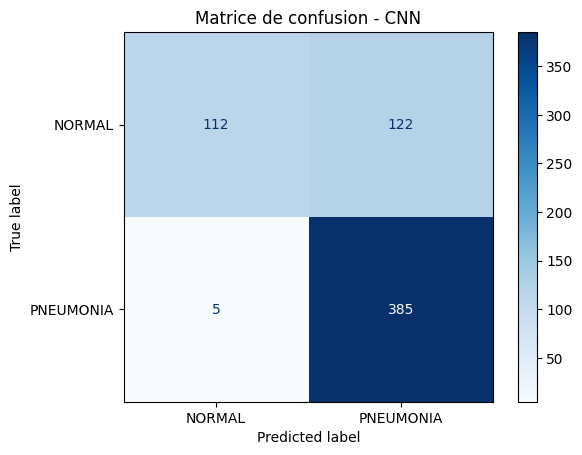

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["NORMAL", "PNEUMONIA"],
    cmap="Blues"
)

plt.title("Matrice de confusion - CNN")
plt.show()

In [ ]:
model.save("chest_xray_cnn.keras")

In [ ]:
from tensorflow import keras

model = keras.models.load_model("chest_xray_cnn.keras")

In [ ]:
print(train_ds.class_names)

['NORMAL', 'PNEUMONIA']
